In [ ]:
# ============================================
# 🎧 Italian Dataset → All Spectrograms in One Folder (/spectrograms/HC)
# ============================================

import os
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
from google.colab import drive

# 1️⃣ Mount Google Drive
drive.mount('/content/drive', force_remount=True)

# 2️⃣ Path setup
input_dir = "/content/drive/MyDrive/italian dataset/HC"  # তোমার HC voice dataset folder
output_dir = "/content/drive/MyDrive/spectrograms/HC"        # সব spectrogram এখানেই সেভ হবে
os.makedirs(output_dir, exist_ok=True)

# 3️⃣ Process each audio file
for filename in os.listdir(input_dir):
    if filename.lower().endswith((".wav", ".mp3", ".flac")):
        file_path = os.path.join(input_dir, filename)
        y, sr = librosa.load(file_path, sr=None)
        duration = librosa.get_duration(y=y, sr=sr)
        segment_length = 10
        num_segments = int(np.ceil(duration / segment_length))
        base_name = os.path.splitext(filename)[0]

        print(f"\n🎵 {filename}: {duration:.2f}s → {num_segments} segments")

        for i in range(num_segments):
            start = i * segment_length
            end = min((i + 1) * segment_length, duration)
            y_segment = y[int(start * sr):int(end * sr)]

            if len(y_segment) == 0:
                continue

            # STFT and dB conversion
            S = np.abs(librosa.stft(y_segment))**2
            DB = librosa.power_to_db(S, ref=np.max)

            # 🎨 Clean spectrogram (no text, no axis, no colorbar)
            fig, ax = plt.subplots(figsize=(10, 4), frameon=False)
            ax.axis('off')
            plt.imshow(DB, aspect='auto', origin='lower', cmap='magma')
            plt.xticks([]); plt.yticks([])
            plt.margins(0, 0)
            plt.subplots_adjust(0, 0, 1, 1, 0, 0)

            # Save
            save_name = f"{base_name}_{start:.0f}-{end:.0f}s.png"
            save_path = os.path.join(output_dir, save_name)
            plt.savefig(save_path, dpi=300, bbox_inches='tight', pad_inches=0)
            plt.close(fig)

            print(f"✅ Saved: {save_path}")

print("\n🎉 সব spectrogram তৈরি হয়ে গেছে!")
print(f"📂 Drive Folder: {output_dir}")

Mounted at /content/drive

🎵 HC5-1.wav: 23.87s → 3 segments
✅ Saved: /content/drive/MyDrive/spectrograms/HC/HC5-1_0-10s.png
✅ Saved: /content/drive/MyDrive/spectrograms/HC/HC5-1_10-20s.png
✅ Saved: /content/drive/MyDrive/spectrograms/HC/HC5-1_20-24s.png

🎵 HC10-1.wav: 24.62s → 3 segments
✅ Saved: /content/drive/MyDrive/spectrograms/HC/HC10-1_0-10s.png
✅ Saved: /content/drive/MyDrive/spectrograms/HC/HC10-1_10-20s.png
✅ Saved: /content/drive/MyDrive/spectrograms/HC/HC10-1_20-25s.png

🎵 HC1-1.wav: 30.73s → 4 segments
✅ Saved: /content/drive/MyDrive/spectrograms/HC/HC1-1_0-10s.png
✅ Saved: /content/drive/MyDrive/spectrograms/HC/HC1-1_10-20s.png
✅ Saved: /content/drive/MyDrive/spectrograms/HC/HC1-1_20-30s.png
✅ Saved: /content/drive/MyDrive/spectrograms/HC/HC1-1_30-31s.png

🎵 HC6-1.wav: 29.06s → 3 segments
✅ Saved: /content/drive/MyDrive/spectrograms/HC/HC6-1_0-10s.png
✅ Saved: /content/drive/MyDrive/spectrograms/HC/HC6-1_10-20s.png
✅ Saved: /content/drive/MyDrive/spectrograms/HC/HC6-1_20-2

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator, img_to_array, load_img
import os
import numpy as np

# 📁 তোমার folder path গুলো
input_dir = "/content/drive/MyDrive/spectrograms/HC"
output_dir = "/content/drive/MyDrive/spectrograms/HC_augmented"

os.makedirs(output_dir, exist_ok=True)

# 🔧 Augmentation setup
datagen = ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Target number (PD এর সমান)
target_count = 298
existing_images = os.listdir(input_dir)
needed = target_count - len(existing_images)

print(f"🔹 Need {needed} new images for balancing")

count = 0
for img_name in existing_images:
    img_path = os.path.join(input_dir, img_name)
    img = load_img(img_path)
    x = img_to_array(img)
    x = np.expand_dims(x, axis=0)

    for batch in datagen.flow(x, batch_size=1,
                              save_to_dir=output_dir,
                              save_prefix='aug',
                              save_format='png'):
        count += 1
        if count >= needed:
            break
    if count >= needed:
        break

print(f"✅ Augmentation complete! New images created: {count}")


🔹 Need 137 new images for balancing
✅ Augmentation complete! New images created: 137


In [ ]:
import shutil, os

source = "/content/drive/MyDrive/spectrograms/HC_augmented"
destination = "/content/drive/MyDrive/spectrograms/HC"

for file_name in os.listdir(source):
    shutil.copy(os.path.join(source, file_name), destination)

print("✅ All augmented images merged into HC folder!")


✅ All augmented images merged into HC folder!


In [ ]:
import os

# Spectrograms ফোল্ডারের path
base_path = "/content/drive/MyDrive/spectrograms"

# ফোল্ডারের নাম
folders = ["HC", "PD"]

for folder in folders:
    folder_path = os.path.join(base_path, folder)
    if os.path.exists(folder_path):
        # শুধুমাত্র image files গুনবো (jpg, png, jpeg)
        images = [f for f in os.listdir(folder_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        print(f"{folder} folder এ মোট {len(images)} টি ছবি আছে।")
    else:
        print(f"{folder} ফোল্ডার পাওয়া যায়নি।")

HC folder এ মোট 298 টি ছবি আছে।
PD folder এ মোট 298 টি ছবি আছে।


In [3]:
# Google Drive মাউন্ট (যদি আগে না করা থাকে)
from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile

# ফোল্ডার পাথ
folder_path = '/content/drive/MyDrive/italian dataset/PD'

# ফোল্ডারে সব .wav ফাইল লিস্ট করা
wav_files = [f for f in os.listdir(folder_path) if f.endswith('PD4-2.wav')]
print(f"মোট {len(wav_files)} টা .wav ফাইল পাওয়া গেছে:")
for f in wav_files:
    print("  -", f)

# প্রত্যেক ফাইলের জন্য স্পেকট্রোগ্রাম বানানো
for file_name in wav_files:
    file_path = os.path.join(folder_path, file_name)

    print(f"\nপ্রসেস করছি: {file_name}")

    try:
        sample_rate, data = wavfile.read(file_path)

        # স্টিরিও হলে মোনো করা
        if len(data.shape) > 1:
            data = np.mean(data, axis=1)

        # প্লট
        plt.figure(figsize=(15, 8))
        plt.specgram(data, Fs=sample_rate, NFFT=2048, noverlap=1024, cmap='magma')
        plt.colorbar(label='Intensity (dB)')
        plt.ylabel('Frequency (Hz)')
        plt.xlabel('Time (seconds)')
        plt.title(f'Spectrogram - {file_name}')
        plt.tight_layout()

        # সেভ করা
        save_name = file_name.replace('.wav', '_spectrogram.png')
        save_path = os.path.join(folder_path, save_name)
        plt.savefig(save_path, dpi=200, bbox_inches='tight')
        plt.close()  # মেমরি বাঁচানোর জন্য

        print(f"সেভ হয়েছে: {save_name}")

    except Exception as e:
        print(f"এরর হয়েছে {file_name} এ: {e}")

print("\nসবগুলো স্পেকট্রোগ্রাম তৈরি হয়ে গেছে! তোমার HC ফোল্ডারে চেক করো।")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
মোট 1 টা .wav ফাইল পাওয়া গেছে:
  - PD4-2.wav

প্রসেস করছি: PD4-2.wav


/tmp/ipython-input-739089875.py:26: WavFileWarning: Chunk (non-data) not understood, skipping it.
  sample_rate, data = wavfile.read(file_path)
/usr/local/lib/python3.12/dist-packages/matplotlib/axes/_axes.py:8233: RuntimeWarning: divide by zero encountered in log10
  Z = 10. * np.log10(spec)


সেভ হয়েছে: PD4-2_spectrogram.png

সবগুলো স্পেকট্রোগ্রাম তৈরি হয়ে গেছে! তোমার HC ফোল্ডারে চেক করো।


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PD ফোল্ডারে পাওয়া গেছে 1 টি ফাইল: ['PD4-2.wav']

প্রসেসিং: PD4-2.wav


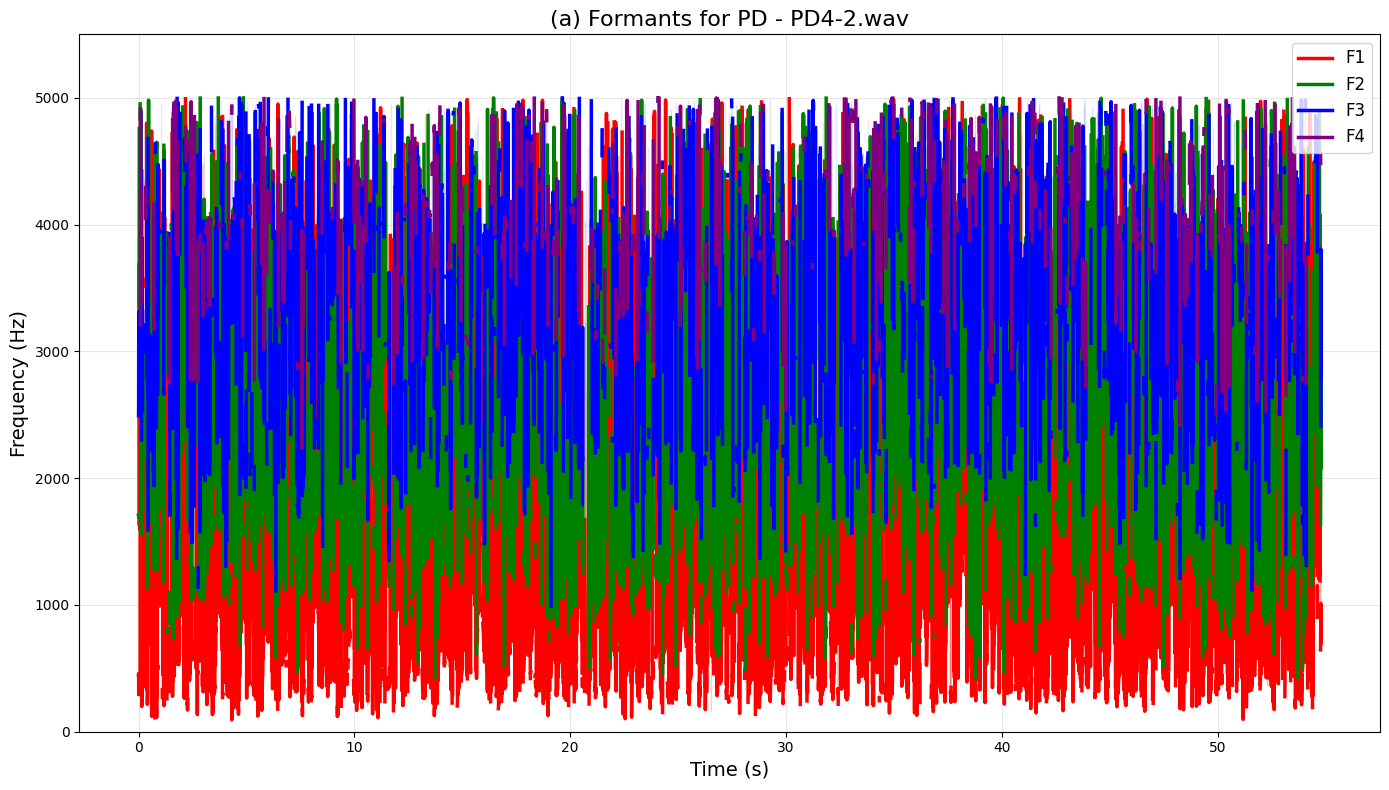

সেভ হয়েছে: PD4-2_formants_PD_style.png

সব PD ফাইলের ফর্ম্যান্ট প্লট তৈরি হয়ে গেছে! PD ফোল্ডারে চেক করো।


In [7]:
# প্রয়োজনীয় লাইব্রেরি (যদি আগে না ইনস্টল করা থাকে)
!pip install librosa numpy matplotlib -q

# ইম্পোর্ট এবং Drive মাউন্ট
from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import matplotlib.pyplot as plt
import librosa

# ফর্ম্যান্ট ট্র্যাক করার ফাংশন (আগের মতোই, কিন্তু আরও স্মুথ)
def track_formants_over_time(audio, sr, num_formants=4, frame_length=0.025, hop_length=0.005):
    frames = librosa.util.frame(audio, frame_length=int(sr * frame_length), hop_length=int(sr * hop_length)).T
    times = np.arange(len(frames)) * hop_length

    formant_tracks = {f'F{i+1}': [] for i in range(num_formants)}

    for frame in frames:
        if np.max(np.abs(frame)) < 1e-5:
            for i in range(num_formants):
                formant_tracks[f'F{i+1}'].append(np.nan)
            continue

        frame = librosa.effects.preemphasis(frame)

        lpc_order = sr // 1000 + num_formants + 2
        if len(frame) <= lpc_order:
            for i in range(num_formants):
                formant_tracks[f'F{i+1}'].append(np.nan)
            continue

        lpc_coeffs = librosa.lpc(frame, order=lpc_order)
        roots = np.roots(lpc_coeffs)
        roots = roots[np.imag(roots) >= 0]

        angles = np.arctan2(np.imag(roots), np.real(roots))
        frequencies = np.sort(angles * (sr / (2 * np.pi)))

        valid_formants = []
        for freq in frequencies:
            if 90 < freq < 5000:  # PD-তে ফর্ম্যান্ট কিছুটা শিফট হতে পারে, রেঞ্জ বড় রাখলাম
                idx = np.argmin(np.abs(angles - np.arctan2(np.imag(roots), np.real(roots))[frequencies == freq]))
                r = np.abs(roots[idx])
                bw = -np.log(r) * (sr / np.pi)
                if bw < 600:
                    valid_formants.append(freq)

        valid_formants = sorted(valid_formants[:num_formants])  # প্রথম ৪টা

        for i in range(num_formants):
            if i < len(valid_formants):
                formant_tracks[f'F{i+1}'].append(valid_formants[i])
            else:
                formant_tracks[f'F{i+1}'].append(np.nan)

    return times, formant_tracks

# PD ফোল্ডার পাথ (যদি নাম অন্যরকম হয় তাহলে চেঞ্জ করো)
folder_path = '/content/drive/MyDrive/italian dataset/PD'

# চেক করি ফোল্ডার আছে কি না
if not os.path.exists(folder_path):
    print("PD ফোল্ডার পাওয়া যায়নি! পাথ চেক করো।")
    print("সম্ভবত পাথ হবে: /content/drive/MyDrive/italian dataset/PD")
else:
    wav_files = [f for f in os.listdir(folder_path) if f.endswith('PD4-2.wav')]
    wav_files.sort()
    print(f"PD ফোল্ডারে পাওয়া গেছে {len(wav_files)} টি ফাইল: {wav_files}")

    colors = {'F1': 'red', 'F2': 'green', 'F3': 'blue', 'F4': 'purple'}

    for file_name in wav_files:
        file_path = os.path.join(folder_path, file_name)
        print(f"\nপ্রসেসিং: {file_name}")

        try:
            audio, sr = librosa.load(file_path, sr=None, mono=True)

            times, formants = track_formants_over_time(audio, sr)

            plt.figure(figsize=(14, 8))

            # লাইন প্লট
            for i in range(1, 5):
                f_key = f'F{i}'
                plt.plot(times, formants[f_key], color=colors[f_key], linewidth=2.5, label=f_key)

            # হালকা ফিল (যেমন তোমার ছবিতে আছে)
            plt.fill_between(times, formants['F1'], formants['F2'], color='red', alpha=0.2)
            plt.fill_between(times, formants['F2'], formants['F3'], color='green', alpha=0.15)
            plt.fill_between(times, formants['F3'], formants['F4'], color='blue', alpha=0.1)

            plt.ylim(0, 5500)
            plt.xlabel('Time (s)', fontsize=14)
            plt.ylabel('Frequency (Hz)', fontsize=14)
            plt.title(f'(a) Formants for PD - {file_name}', fontsize=16)
            plt.legend(loc='upper right', fontsize=12)
            plt.grid(True, alpha=0.3)
            plt.tight_layout()

            # সেভ করা
            save_path = os.path.join(folder_path, file_name.replace('.wav', '_formants_PD_style.png'))
            plt.savefig(save_path, dpi=200, bbox_inches='tight')
            plt.show()

            print(f"সেভ হয়েছে: {os.path.basename(save_path)}")

        except Exception as e:
            print(f"এরর {file_name}-এ: {e}")

    print("\nসব PD ফাইলের ফর্ম্যান্ট প্লট তৈরি হয়ে গেছে! PD ফোল্ডারে চেক করো।")